# Four aggregate return curves from `plot_iqm.py --compute-only`

Generate the four CSVs with `plot_iqm.py --compute-only`, then edit `PLOTS` in the setup cell to choose each CSV path, panel title, timesteps per task, curve color, and environment maximum return. The list order maps to the 2 × 2 grid in reading order: (a), (b), (c), (d). Each CSV should contain one panel; the notebook divides its saved center and uncertainty bounds by the configured maximum return without recomputing or smoothing them.

In [19]:
from pathlib import Path
import sys

STYLE_ROOT = Path.cwd()
if not (STYLE_ROOT / "scripts" / "plot_style.py").is_file():
    STYLE_ROOT = STYLE_ROOT.parent
if not (STYLE_ROOT / "scripts" / "plot_style.py").is_file():
    raise FileNotFoundError("Start the notebook in the repository root or scripts/.")
sys.path.insert(0, str(STYLE_ROOT))
sys.path.insert(0, str(STYLE_ROOT / "scripts"))
# Reload edits from disk when rerunning this cell in an existing kernel.
import importlib
from scripts import plot_style
importlib.reload(plot_style)
from scripts.plot_style import (
    apply_style, figure_size, export_figure, bottom_legend, COMPARISON_LEGEND_PLACEMENT, FONT_SIZE, STROKES,
)
apply_style()

import shutil
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

# Works when the kernel starts in either the repository root or scripts/.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "scripts" / "plot_iqm.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "scripts" / "plot_iqm.py").exists():
    raise FileNotFoundError("Start the notebook in the repository root or scripts/.")

# (CSV path, panel title, timesteps per task, main curve color, maximum return), in grid order.

PLOTS = [
     (PROJECT_ROOT / "output/plots/paper/sac_ip_mt_data.csv", "Multitask training", 100_000, "#3A9AB2", 1000.0),
     (PROJECT_ROOT / "output/plots/paper/sac_ip_ft_data.csv", "Sequential fine-tuning", 100_000, "#3A9AB2", 1000.0),
]

X_LABEL = r"Cumulative training timesteps ($\times 10^5$)"
Y_LABEL = "Normalized return"
OUT = PROJECT_ROOT / "output/plots/notebook"
OUTPUT_STEM = "mt_vs_ft_side_by_side"
SAVE = True

# Optional overrides keyed by (grid position 0-3, line_index or method).
LINE_LABELS = {}  # Example: {(0, 0): "Raw", (0, 1): "EMA (span 5)"}
LINE_COLORS = {}  # Example: {(0, 0): "#3A9AB2", (0, 1): "#EBCC2A"}
PALETTE = ["#E69F00", "#009E73", "#56B4E9"]




plt.rcParams['svg.fonttype'] = 'none'

In [20]:
REQUIRED = {"label", "method", "test_env", "aggregation", "timestep", "center", "lower", "upper"}

def load_plot_data(path: Path) -> pd.DataFrame:
    if not path.is_file():
        raise FileNotFoundError(
            f"{path}\nGenerate it with plot_iqm.py --compute-only or update PLOTS."
        )
    frame = pd.read_csv(path, dtype={"test_env": str})
    missing = REQUIRED.difference(frame.columns)
    if missing:
        raise ValueError(f"{path}: missing compute-only columns: {sorted(missing)}")
    if frame.empty:
        raise ValueError(f"No rows in {path}")
    for column in ("timestep", "center", "lower", "upper"):
        frame[column] = pd.to_numeric(frame[column], errors="raise")
    valid = np.isfinite(frame[["timestep", "center", "lower", "upper"]].to_numpy()).all(axis=1)
    if not valid.all():
        print(f"{path.name}: skipped {(~valid).sum()} rows with non-finite plotted values.")
        frame = frame.loc[valid].copy()
    if frame.empty:
        raise ValueError(f"No finite curve rows remain in {path}")
    if (frame["lower"] > frame["upper"]).any():
        raise ValueError(f"{path}: found lower bounds above upper bounds.")
    if "plot_index" in frame:
        if "line_index" not in frame:
            raise ValueError(f"{path}: plot_index requires line_index.")
        frame["plot_index"] = pd.to_numeric(frame["plot_index"], errors="raise").astype(int)
        frame["line_index"] = pd.to_numeric(frame["line_index"], errors="raise").astype(int)
    return frame

if len(PLOTS) != 2:
    raise ValueError("PLOTS must contain exactly four (path, title, task interval, color, maximum return) entries.")

plot_data = []
for path, title, timesteps_per_task, plot_color, max_return in PLOTS:
    if not np.isfinite(max_return) or max_return <= 0:
        raise ValueError(f"{path}: maximum return must be positive and finite.")
    frame = load_plot_data(path)
    panel_column = "plot_index" if "plot_index" in frame else "test_env"
    if frame[panel_column].nunique(dropna=False) != 1:
        raise ValueError(f"{path} contains multiple panels; use one panel per CSV.")
    line_column = "line_index" if "plot_index" in frame else "method"
    plot_data.append((title, frame, line_column, timesteps_per_task, plot_color, max_return))
    print(f"{path.name}: {len(frame):,} rows, {frame[line_column].nunique()} lines, "
          f"{timesteps_per_task:,} timesteps/task, maximum return {max_return:g}")

sac_ip_mt_data.csv: 720 rows, 3 lines, 100,000 timesteps/task, maximum return 1000
sac_ip_ft_data.csv: 2,160 rows, 3 lines, 100,000 timesteps/task, maximum return 1000


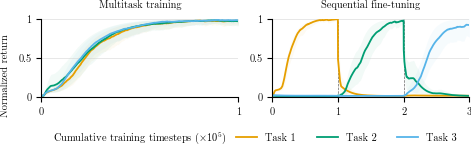

In [21]:
def format_timestep(value, _position):
    return f"{value / 100_000:g}"

def plot_aggregate_curves(plot_data):
    fig, axes = plt.subplots(
        1, 2, figsize=figure_size(3.0), squeeze=False, layout="constrained",
    )
    color_ix = 0
    for grid_index, (ax, (title, panel, line_column, timesteps_per_task, plot_color, max_return)) in enumerate(
        zip(axes.flat, plot_data)
    ):
        if timesteps_per_task <= 0:
            raise ValueError(f"Grid position {grid_index + 1}: timesteps per task must be positive.")
        metrics = panel["aggregation"].dropna().unique()
        if len(metrics) != 1:
            raise ValueError(f"Grid position {grid_index + 1} must have one aggregation: {metrics}")
        ax.set_title(title, pad=8)


        lines = list(panel.groupby(line_column, sort=False))
        labels = []
        for line_key, line in lines:
            override = LINE_LABELS.get((grid_index, line_key))
            label = override or str(line["label"].iloc[0]).strip()
            if not label or label.lower() == "nan":
                label = str(line["method"].iloc[0]).split("/")[-1].replace("_", " ")
            labels.append(label)
        duplicates = {label for label in labels if labels.count(label) > 1}

        for idx, ((line_key, line), label) in enumerate(zip(lines, labels)):
            line = line.sort_values("timestep")
            default_color = PALETTE[color_ix % len(PALETTE)]
            color_ix += 1
            color = LINE_COLORS.get((grid_index, line_key), default_color)
            display_label = f"{label} (line {idx + 1})" if label in duplicates else label
            x = line["timestep"].to_numpy(dtype=float)
            center = line["center"].to_numpy(dtype=float) / max_return
            lower = line["lower"].to_numpy(dtype=float) / max_return
            upper = line["upper"].to_numpy(dtype=float) / max_return
            ax.plot(x, center, color=color, label=display_label)
            ax.fill_between(x, lower, upper, color=color, alpha=0.05, linewidth=STROKES["band_edge"])

        xmax = float(panel["timestep"].max())
        ax.set_xlim(0, xmax)
        ax.set_ylim(0, 1)
        ax.set_yticks([0, 0.5, 1], labels=["0", "0.5", "1"])
        task_boundaries = np.arange(0, xmax + 1, timesteps_per_task)
        ax.set_xticks(task_boundaries)
        for boundary in task_boundaries[1:]:
            if boundary < xmax:
                ax.axvline(boundary, color="0.4", linewidth=STROKES["task_boundary"], linestyle="--", zorder=0)
        ax.xaxis.set_major_formatter(FuncFormatter(format_timestep))
        ax.grid(axis="y", color="0.8", alpha=0.65)
        ax.spines[["top", "right"]].set_visible(False)
        handles, labels = ax.get_legend_handles_labels()


    fig.supxlabel(X_LABEL)
    bottom_legend(fig, handles, labels, ncol=3,
                  placement=COMPARISON_LEGEND_PLACEMENT)

    fig.supylabel(Y_LABEL)
    return fig

fig = plot_aggregate_curves(plot_data)
plt.show()

In [22]:
if SAVE:
    OUT.mkdir(parents=True, exist_ok=True)
    for suffix in ("pdf", "png", "svg"):
        path = OUT / f"{OUTPUT_STEM}.{suffix}"
        export_figure(fig, path, dpi=300)
        print(f"Saved {path}")

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
webf NOT subset; don't know how to subset; dropped


Saved /home/seb/Code/uni/stability-gap-drl/output/plots/notebook/mt_vs_ft_side_by_side.pdf
Saved /home/seb/Code/uni/stability-gap-drl/output/plots/notebook/mt_vs_ft_side_by_side.png
Saved /home/seb/Code/uni/stability-gap-drl/output/plots/notebook/mt_vs_ft_side_by_side.svg
